### Alzheimer's Progression Prediction model 
##### via MRI image dataset from OASIS Alzheimer's dataset
---
Rudy Gamboa | Alex Hernandez | Jeff Ock

In [159]:
## Import modules
# for Data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
# from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
# for Model
import tensorflow as tf
from tensorflow import keras
import tensorflow.keras                             # type: ignore
from tensorflow.keras.layers import Dense,Dropout   # type: ignore
from tensorflow.keras.applications import MobileNet # type: ignore
from tensorflow.keras.models import Model           # type: ignore
from tensorflow.keras.optimizers import Adam        # type: ignore
# for Other
import os
import cv2
from tqdm import tqdm
import io
import seaborn as sns

---
##### Get Data:
---

In [160]:
# Specify the path to the main data folder
cwd = os.getcwd()
train_path = os.path.join(cwd, "Alzheimers-ADNI", "train")
test_path = os.path.join(cwd, "Alzheimers-ADNI", "test")

train_datagen = ImageDataGenerator(
    validation_split=0.2  # 20% validation split
)

# Create train_generator iterator object
train_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='training',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Create train_generator iterator object
val_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='validation',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Test data generator
test_datagen = ImageDataGenerator(rescale=1./255)  # Only rescaling, no augmentation

# Test generator
test_generator = test_datagen.flow_from_directory(
    test_path, 
    target_size=(256, 256),
    color_mode='rgb',
    batch_size=16,
    seed=1,
    class_mode='categorical',
    shuffle=False  # Do not shuffle to keep predictions in order
)


Found 12974 images belonging to 5 classes.
Found 3242 images belonging to 5 classes.
Found 2575 images belonging to 5 classes.


In [161]:
labels = ['Reduced AD','Reduced CN', 'Reduced EMCI', 'Reduced LMCI','Reduced MCI']
labels = ['Final AD JPEG','Final CN JPEG', 'Final EMCI JPEG', 'Final LMCI JPEG','Final MCI JPEG']

X_train = []  # Training Dataset
Y_train = []  # Training Labels
image_size = 150

cwd = os.getcwd()  # Current working directory

for i in labels:
    folderPath = os.path.join(cwd, "Alzheimers-ADNI", "train", i)
    for j in tqdm(os.listdir(folderPath)):
        image_path = os.path.join(folderPath, j)
        image = cv2.imread(image_path)
        if image is None:
            print(f"Warning: Unable to load image at {image_path}")
            continue
        image = cv2.resize(image, (image_size, image_size))
        X_train.append(image)
        Y_train.append(i)

# Convert lists to numpy arrays
Xtrain = np.array(X_train)
Ytrain = np.array(Y_train)

X_test = []  # Test Dataset
Y_test = []  # Training Labels
image_size = 150

cwd = os.getcwd()  # Current working directory

for i in labels:
    folderPath = os.path.join(cwd, "Alzheimers-ADNI", "test", i)
    for j in tqdm(os.listdir(folderPath)):
        image_path = os.path.join(folderPath, j)
        image = cv2.imread(image_path)
        if image is None:
            print(f"Warning: Unable to load image at {image_path}")
            continue
        image = cv2.resize(image, (image_size, image_size))
        X_test.append(image)
        Y_test.append(i)

# Convert lists to numpy arrays
Xtest = np.array(X_test)
Ytest = np.array(Y_test)

print(f"Final train dataset size: {Xtrain.shape}, Labels: {Ytrain.shape}")
print(f"Final test dataset size: {Xtest.shape}, Labels: {Ytest.shape}")

100%|██████████| 233/233 [00:01<00:00, 127.94it/s]


Final train dataset size: (16216, 150, 150, 3), Labels: (16216,)
Final test dataset size: (2575, 150, 150, 3), Labels: (2575,)


---
##### Data Exploration:
---

In [162]:
# Create a mapping from class numbers to class names
class_mapping = {idx: label for idx, label in enumerate(labels)}

# Print the mapping
print("Class Number to Class Name Mapping:")
for class_num, class_name in class_mapping.items():
    print(f"Class {class_num}: {class_name}")

Class Number to Class Name Mapping:
Class 0: Final AD JPEG
Class 1: Final CN JPEG
Class 2: Final EMCI JPEG
Class 3: Final LMCI JPEG
Class 4: Final MCI JPEG


In [163]:
# Baseline Accuracy
baseline_acc = 150/672
print(baseline_acc)

0.22321428571428573


Image example: Final MCI JPEG


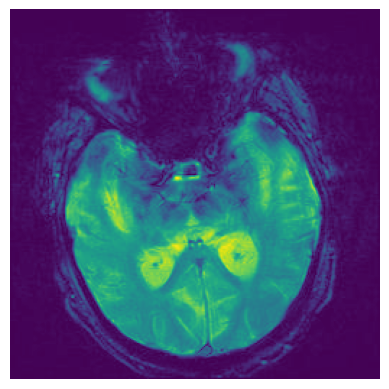

Image dimensions: (256, 256)
Number of channels: 3


In [164]:
# Get random image from Reduced AD
labels = os.listdir(train_path)
random_label = np.random.choice(labels)
random_img = np.random.choice((os.listdir(os.path.join(train_path, random_label))))
img_path = os.path.join(train_path, random_label, random_img)
img = plt.imread(img_path)

# Display the above image
print("Image example:", random_label)
plt.imshow(img)
plt.axis('off')
plt.show()

# Image info
print("Image dimensions:", img.shape[0:2])
print("Number of channels:", "3")

In [165]:
# Number of samples
print("Number of samples by class:")
for label in sorted(labels):
  print(f"- {label}: {len(os.listdir(os.path.join(train_path, label)))}")

Number of samples by class:
- Final AD JPEG: 7552
- Final CN JPEG: 7430
- Final EMCI JPEG: 240
- Final LMCI JPEG: 72
- Final MCI JPEG: 922


---
##### Data Curation:
---

In [166]:
# code...

---
##### Data Augmentation / Feature Engineering:
---

In [167]:
# code...

---
##### Final Data Visualization:
---

In [168]:
# code...

---
##### Define Model:
---

In [196]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Flatten, TimeDistributed, LSTM
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import models
from tensorflow.keras import regularizers
from tensorflow.keras import layers
import numpy as np

# Encode labels to integers
label_encoder = LabelEncoder()
Ytrain_encoded = label_encoder.fit_transform(Ytrain)
Ytest_encoded = label_encoder.transform(Ytest)

# Convert labels to one-hot encoding
Ytrain_onehot = to_categorical(Ytrain_encoded)
Ytest_onehot = to_categorical(Ytest_encoded)

# Reshape image data to treat each row as a sequence
# Assuming images are already normalized
Xtrain_rnn = Xtrain.reshape(Xtrain.shape[0], image_size, image_size * 3)  # Flatten columns in each row
Xtest_rnn = Xtest.reshape(Xtest.shape[0], image_size, image_size * 3)


In [186]:
# Base model, TBD
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(256, 256, 3))

# L2 regularizer
l2_reg = regularizers.l2(0.0001)

# Build the improved model
model = models.Sequential()
model.add(base_model)
model.add(layers.GlobalAveragePooling2D())  # Replaces Flatten for better efficiency

# Add dense layers with L2 regularization and batch normalization
model.add(layers.Dense(1024, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.4))  # Adjusted Dropout

model.add(layers.Dense(512, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.4))  # Adjusted Dropout

model.add(layers.Dense(256, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

model.add(layers.Dense(128, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

model.add(layers.Dense(64, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.BatchNormalization())  # Added batch normalization
model.add(layers.Dropout(0.3))  # Adjusted Dropout

# Output layer
model.add(layers.Dense(5, activation='softmax'))  # Output layer for 5 classes

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])


In [172]:
# RNN Model
modelRNN = Sequential()
# Add LSTM layers with Dropout for regularization
modelRNN.add(LSTM(128, input_shape=(image_size, image_size * 3), return_sequences=True, dropout=0.3, recurrent_dropout=0.2))
modelRNN.add(LSTM(64, return_sequences=False, dropout=0.3, recurrent_dropout=0.2))
# Add fully connected (Dense) layers with Dropout
modelRNN.add(Dense(32, activation='relu'))
modelRNN.add(Dropout(0.4))  # Dropout on the dense layer
# Output layer
modelRNN.add(Dense(len(labels), activation='softmax'))

modelRNN.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])

C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [198]:
from tensorflow.keras.layers import Bidirectional

# BiLSTM Model
modelBiLSTM = Sequential()
# Add Bidirectional LSTM layers with Dropout
modelBiLSTM.add(Bidirectional(LSTM(128, return_sequences=True, dropout=0.3, recurrent_dropout=0.2), 
                               input_shape=(image_size, image_size * 3)))
modelBiLSTM.add(Bidirectional(LSTM(64, return_sequences=False, dropout=0.3, recurrent_dropout=0.2)))
# Add fully connected (Dense) layers with Dropout
modelBiLSTM.add(Dense(32, activation='relu'))
modelBiLSTM.add(Dropout(0.4))  # Dropout on the dense layer
# Output layer
modelBiLSTM.add(Dense(len(labels), activation='softmax'))

# Compile the model
modelBiLSTM.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])

C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


---
##### Model Training:
---

In [203]:
from tensorflow.keras.backend import clear_session

clear_session()  # Clear the backend session

# Train the model
history = modelBiLSTM.fit(
    Xtrain_rnn, Ytrain_onehot,
    validation_data=(Xtest_rnn, Ytest_onehot),
    epochs=25,
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = modelBiLSTM.evaluate(Xtest_rnn, Ytest_onehot)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")

Epoch 1/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 178s 345ms/step - accuracy: 0.5621 - loss: 0.7656 - val_accuracy: 0.5017 - val_loss: 1.0754
Epoch 2/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 182s 358ms/step - accuracy: 0.5463 - loss: 0.7587 - val_accuracy: 0.5487 - val_loss: 1.0610
Epoch 3/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 179s 352ms/step - accuracy: 0.5779 - loss: 0.7463 - val_accuracy: 0.5390 - val_loss: 1.0547
Epoch 4/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 180s 355ms/step - accuracy: 0.5990 - loss: 0.7426 - val_accuracy: 0.5456 - val_loss: 1.0369
Epoch 5/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 179s 353ms/step - accuracy: 0.5881 - loss: 0.7317 - val_accuracy: 0.5317 - val_loss: 1.0375
Epoch 6/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 179s 354ms/step - accuracy: 0.5864 - loss: 0.7325 - val_accuracy: 0.5367 - val_loss: 1.0457
Epoch 7/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 176s 348ms/step - accuracy: 0.6076 - loss: 0.7243 - val_accuracy: 0.5417 - val_loss: 1.0165
Epoch 8/25
507/507 ━━━━━━━━━━━━━━━━━━━━ 207s 407ms/step - accuracy: 0.6303 -

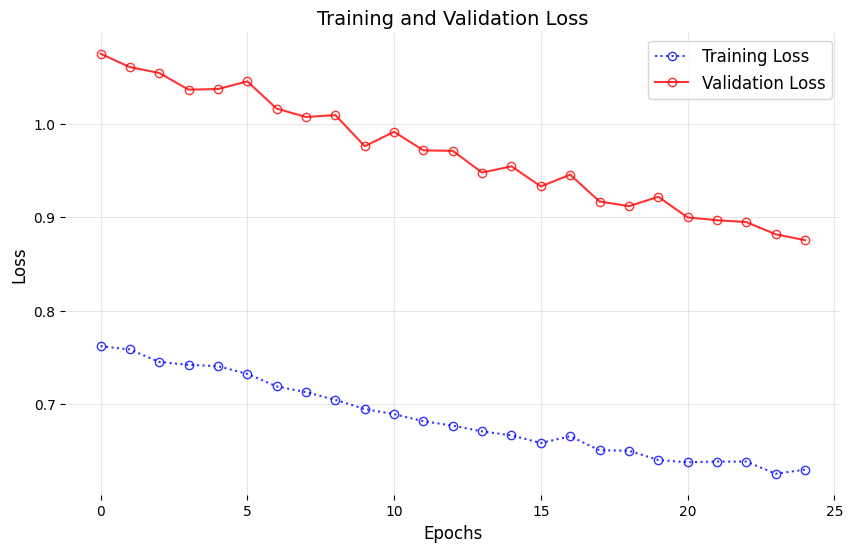

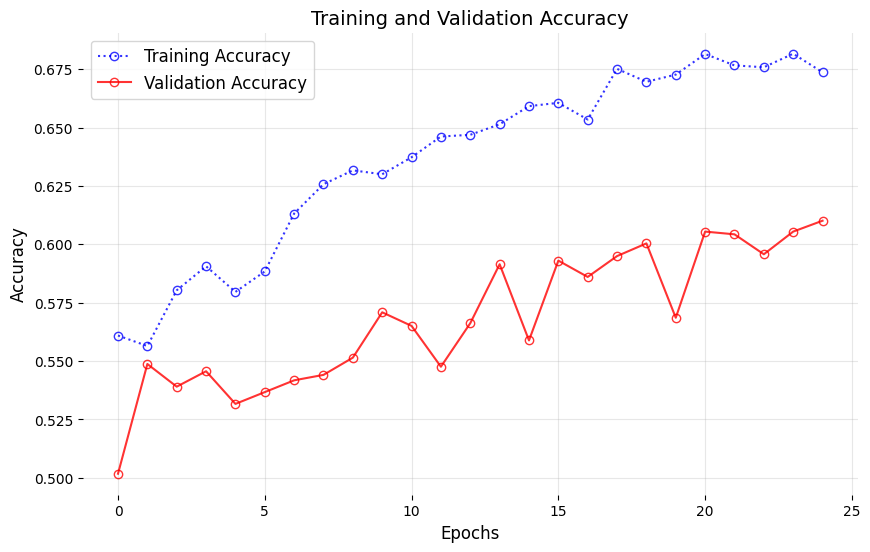

In [204]:

# Plot Training and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['loss'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Loss'
)
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

# Plot Training and Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['accuracy'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Accuracy'
)
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

---
##### Model Testing:
---

81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step


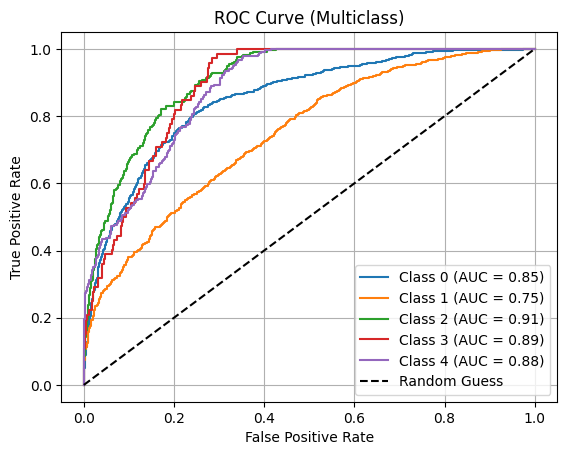

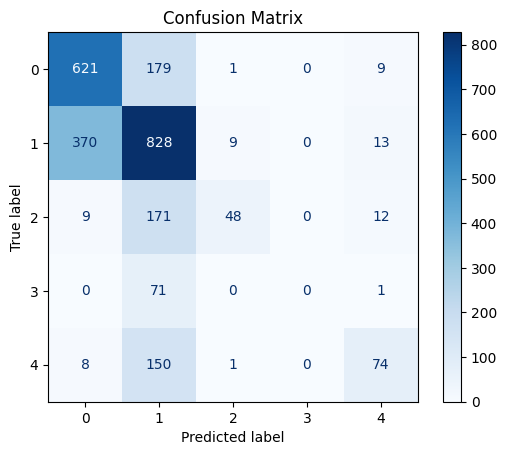

Confusion Matrix:
[[621 179   1   0   9]
 [370 828   9   0  13]
 [  9 171  48   0  12]
 [  0  71   0   0   1]
 [  8 150   1   0  74]]


In [205]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Get predictions
Ypred_probs = modelBiLSTM.predict(Xtest_rnn)  # Predicted probabilities
Ypred_classes = np.argmax(Ypred_probs, axis=1)  # Predicted classes
Ytrue_classes = np.argmax(Ytest_onehot, axis=1)  # True classes

# Plot ROC Curve
if Ytest_onehot.shape[1] == 2:  # Binary classification
    fpr, tpr, _ = roc_curve(Ytrue_classes, Ypred_probs[:, 1])  # Use probabilities for the positive class
    auc_score = roc_auc_score(Ytrue_classes, Ypred_probs[:, 1])

    plt.figure()
    plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.2f})")
    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid()
    plt.show()
else:  # Multiclass classification (macro-average AUC)
    # Compute ROC curve and AUC for each class
    for i in range(Ytest_onehot.shape[1]):
        fpr, tpr, _ = roc_curve(Ytest_onehot[:, i], Ypred_probs[:, i])
        auc_score = roc_auc_score(Ytest_onehot[:, i], Ypred_probs[:, i])
        plt.plot(fpr, tpr, label=f"Class {i} (AUC = {auc_score:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve (Multiclass)")
    plt.legend()
    plt.grid()
    plt.show()

# Confusion Matrix
conf_matrix = confusion_matrix(Ytrue_classes, Ypred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=np.unique(Ytrue_classes))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

# Print Metrics
print("Confusion Matrix:")
print(conf_matrix)


---
##### Final Results:
---

In [ ]:
# code...